# 4buwan — Calibration v2
## Genuine-Only Writer-Adaptive Calibration of One-Class SVMs for Offline Signature Verification

**Supersedes:** `4buwan_calibration_v1.ipynb` · **Prior study:** 6buwan (RAW-vs-HOG comparative)

---

## What v1 established

v1 ran on real CEDAR and the calibration worked:

| Metric (HOG) | fixed (6buwan) | calibrated (v1) | test |
|---|---|---|---|
| FRR | 81.36% | **43.18%** | p = 1.6e-9, better on 48/55 writers |
| F1 | 0.293 | **0.604** | p = 9.4e-9 |
| Balanced accuracy | 59.32% | **72.23%** | |
| Accuracy | 72.88% | **77.37%** | p = 0.012 |
| FAR | 0.00% | 12.35% | p = 0.0006 (the cost) |

The abolished validation partition also fixed the power problem: **52 informative pairs**
instead of v1-of-6buwan's 28.

## What v1 got wrong — and what v2 fixes

**1. The RBF kernel went degenerate.** v1 selected gamma values of 5e-11, 1.4e-11,
8e-12. With `exp(-gamma * d^2)` and gamma that small, the kernel evaluates to ~1.0 for
every pair: the boundary stops discriminating. The search found it could satisfy the
acceptance target by flattening the kernel rather than by placing a better boundary.

Evidence it mattered: **ROC-AUC fell** (0.9512 -> 0.9199) while every thresholded
metric improved. Ranking quality got worse even as the operating point got better.

The 6buwan notebook already had the right diagnostic — `kernel_scale_check`, flagging
`gamma x mean_sq_dist < 0.01` as near-degenerate. Because
`gamma_reference = 1 / median_sq_dist`, that product **is the multiplier**. So:

> **the edge-binding failure and the degeneracy are the same problem**, and a floor on
> the gamma multiplier fixes both.

v2 adds `KERNEL_SCALE_MIN` and runs the calibration **both ways**, so the data decides
whether a non-degenerate boundary can still deliver the improvement.

**2. "Threshold placement" was imprecise.** Changing nu and gamma **refits the OCSVM
boundary**; it is not a post-hoc adjustment of the decision score. v1's framing was
loose and a panel would catch it. Correct statement:

> The separating information is present (median per-writer AUC 0.95+), but the
> **fitted boundary** under one global (nu, gamma) does not enclose each writer's own
> genuine variation. This study refits that boundary per writer from genuine-only data.

**3. Nearly half the corpus fell to the fallback tier** (RAW 23/55, HOG 22/55). Part 9
now diagnoses *why*, including the quantisation effect: with 12 LOO samples, acceptance
can only take values k/12, so a 0.70 target actually demands >= 9/12 = 0.75.

## New in v2

- `SKIP_VERIFICATION` — Part 1 is slow (MD5 over 2,640 images) and already passed; skipped by default
- **Kernel non-degeneracy constraint**, reported both on and off
- **ROC-AUC tracked through the sweep**, so ranking quality is visible alongside FAR/FRR
- **Preprocessing experiment** (Part 13): three variants under an identical split
- **Runtime timer** reported at the end

---
## Part 0 — Setup

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
import numpy as np, pandas as pd
from PIL import Image, ImageOps
from math import floor, ceil
from skimage.feature import hog
from skimage.filters import threshold_otsu
from skimage.morphology import skeletonize
from sklearn.preprocessing import StandardScaler
from sklearn.svm import OneClassSVM
from sklearn.metrics import roc_auc_score
from scipy import stats
import matplotlib.pyplot as plt
import os, hashlib, random, time
from pathlib import Path
from collections import Counter

try:
    import cv2
    HAVE_CV2 = True
except ImportError:
    HAVE_CV2 = False

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED); random.seed(RANDOM_SEED)

# ---------------- RUNTIME TIMER ----------------
NB_T0 = time.time()
SECTION_TIMES = {}

def mark(section):
    """Record elapsed time for a named section and print it."""
    now = time.time()
    prev = SECTION_TIMES.get("_last", NB_T0)
    SECTION_TIMES[section] = now - prev
    SECTION_TIMES["_last"] = now
    print(f"[timer] {section}: {now - prev:.1f}s   (total {now - NB_T0:.1f}s)")

print("Imports loaded. Seed =", RANDOM_SEED, "| OpenCV:", HAVE_CV2)
print("Timer started.")

Imports loaded. Seed = 42 | OpenCV: True
Timer started.


In [3]:
# ---------------- CONFIGURATION ----------------
DATASET_DIR = Path("/content/drive/MyDrive/cedar-dataset-thesis/signatures")
GENUINE_DIR = DATASET_DIR / "full_org"
FORGED_DIR  = DATASET_DIR / "full_forg"

SKIP_VERIFICATION = True      # Part 1 already passed in v1; MD5 over 2,640 images is slow

IMG_SIZE        = (100, 100)
MAX_CROP_ASPECT = 2.5
DENSITY_FRAC    = 0.05

N_WRITERS       = 55
N_TRAIN_GENUINE = 12

# 6buwan locked hyperparameters -> the BASELINE (control) condition
V1_LOCKED = {"RAW": {"nu": 0.15, "gamma": 3.007e-06},
             "HOG": {"nu": 0.20, "gamma": 2.296e-06}}

# ---- calibration targets ----
TARGET_ACCEPT        = 0.70
TARGET_COHORT_REJECT = 0.95
COHORT_PER_WRITER    = 2

# ---- NEW IN v2: kernel non-degeneracy floor ----
# The gamma multiplier IS the product (gamma x median_sq_dist), so a floor on the
# multiplier is exactly the kernel_scale_check from 6buwan. Below ~0.01 the RBF
# kernel is effectively flat and the boundary stops discriminating.
KERNEL_SCALE_MIN = 0.01       # set to None to reproduce v1's unconstrained behaviour

print("Config set.")
print(f"  SKIP_VERIFICATION = {SKIP_VERIFICATION}")
print(f"  KERNEL_SCALE_MIN  = {KERNEL_SCALE_MIN}  (None = v1 behaviour)")

Config set.
  SKIP_VERIFICATION = True
  KERNEL_SCALE_MIN  = 0.01  (None = v1 behaviour)


---
## Part 1 — Dataset verification *(skipped by default)*

Passed in v1: 1,320 genuine + 1,320 forged, 24 of each per writer, no duplicates
within or across classes. Set `SKIP_VERIFICATION = False` to re-run — the MD5 pass
over 2,640 images is the slow part.

In [4]:
genuine_files = sorted(GENUINE_DIR.glob("*.png"))
forged_files  = sorted(FORGED_DIR.glob("*.png"))

def get_writer_id(filepath):
    return int(Path(filepath).stem.split("_")[1])

print("Genuine PNG files:", len(genuine_files))
print("Forged  PNG files:", len(forged_files))
assert len(genuine_files) == 1320 and len(forged_files) == 1320

if SKIP_VERIFICATION:
    print("\n[SKIPPED] full verification -- passed in v1 "
          "(counts, per-writer 24/24, no duplicates within or across classes)")
else:
    gc_, fc_ = Counter(map(get_writer_id, genuine_files)), Counter(map(get_writer_id, forged_files))
    assert all(gc_[w] == 24 for w in range(1, N_WRITERS + 1))
    assert all(fc_[w] == 24 for w in range(1, N_WRITERS + 1))
    def image_hash(p): return hashlib.md5(Path(p).read_bytes()).hexdigest()
    gh = {}; dg = 0
    for f in genuine_files:
        h = image_hash(f); dg += h in gh; gh[h] = f
    fh = {}; df_ = 0; dx = 0
    for f in forged_files:
        h = image_hash(f); df_ += h in fh; fh[h] = f; dx += h in gh
    assert dg == 0 and df_ == 0 and dx == 0, "duplicates found"
    print("\nFull dataset verification PASSED.")

mark("Part 1 dataset")

Genuine PNG files: 1320
Forged  PNG files: 1320

[SKIPPED] full verification -- passed in v1 (counts, per-writer 24/24, no duplicates within or across classes)
[timer] Part 1 dataset: 0.1s   (total 0.1s)


---
## Part 2 — Writer-specific split *(unchanged from v1)*

In [5]:
rng_split = random.Random(RANDOM_SEED)
writer_splits = {}
for wid in range(1, N_WRITERS + 1):
    g = sorted([p for p in genuine_files if get_writer_id(p) == wid])
    f = sorted([p for p in forged_files  if get_writer_id(p) == wid])
    sg = g.copy(); rng_split.shuffle(sg)
    sf = f.copy(); rng_split.shuffle(sf)
    writer_splits[wid] = {"train_genuine": sg[:N_TRAIN_GENUINE],
                          "test_genuine":  sg[N_TRAIN_GENUINE:],
                          "test_forged":   sf}

for wid, s in writer_splits.items():
    assert len(s["train_genuine"]) == 12 and len(s["test_genuine"]) == 12 and len(s["test_forged"]) == 24
    assert not (set(s["train_genuine"]) & set(s["test_genuine"]))

train_files        = [p for s in writer_splits.values() for p in s["train_genuine"]]
test_genuine_files = [p for s in writer_splits.values() for p in s["test_genuine"]]
test_forged_files  = [p for s in writer_splits.values() for p in s["test_forged"]]

print(f"Split OK -- train {len(train_files)} | test genuine {len(test_genuine_files)} | test forged {len(test_forged_files)}")
mark("Part 2 split")

Split OK -- train 660 | test genuine 660 | test forged 1320
[timer] Part 2 split: 0.7s   (total 0.8s)


---
## Part 3 — Preprocessing: three variants

v1 used variant **A** only. The 2016-era `OCSVM_signature_verification` notebook
produces visually crisper images via Gaussian blur + Otsu binarisation, which raised
the question of whether that helps verification or only appearance.

**It is an empirical question, and sharper is not automatically better.** Hard
binarisation discards stroke-intensity information; thinning additionally discards
stroke-width information. Either could help or hurt depending on the feature extractor.
HOG in particular reads gradient structure, which binarisation changes substantially.

So all three are run under an identical split and compared on FAR / FRR / F1 /
balanced accuracy / AUC — not on how they look.

| Variant | Description |
|---|---|
| **A** | v1 pipeline: invert, Otsu-mask, density-crop, aspect cap, resize+pad, grayscale retained |
| **B** | A + Gaussian blur then Otsu **binarisation** (crisp binary strokes) |
| **C** | B + morphological **thinning** (skeleton) |

One implementation point that matters: because occlusion attribution recomputes
features from the preprocessed image, the attribution function must use the **same
variant** as the model being explained, or the heatmap explains a different model.

In [6]:
def _common_geometry(img, max_aspect=MAX_CROP_ASPECT, density_frac=DENSITY_FRAC,
                     img_size=IMG_SIZE):
    """Shared geometry: density-crop -> aspect cap -> resize preserving aspect -> pad."""
    target_width, target_height = img_size

    if img.max() > img.min():
        ink_mask = img > threshold_otsu(img)
    else:
        ink_mask = np.zeros_like(img, dtype=bool)

    if ink_mask.any():
        rc = ink_mask.sum(axis=1); cc = ink_mask.sum(axis=0)
        rt = max(2, rc.max() * density_frac); ct = max(2, cc.max() * density_frac)
        sr = rc >= rt; sc = cc >= ct
        if sr.any() and sc.any():
            t, b = np.where(sr)[0][[0, -1]]; l, r = np.where(sc)[0][[0, -1]]
            img = img[t:b+1, l:r+1]

    h, w = img.shape
    if w / h > max_aspect:
        pad = max(0, ceil(w / max_aspect) - h)
        img = np.pad(img, ((pad//2, pad - pad//2), (0, 0)), constant_values=0)
    elif h / w > max_aspect:
        pad = max(0, ceil(h / max_aspect) - w)
        img = np.pad(img, ((0, 0), (pad//2, pad - pad//2)), constant_values=0)

    h, w = img.shape
    nw = min(target_width, max(1, w * target_height // h))
    nh = max(1, h * nw // w)
    img = np.asarray(Image.fromarray(img.astype(np.uint8)).resize((nw, nh)))

    top = floor((target_height - nh)/2); bot = ceil((target_height - nh)/2)
    lef = floor((target_width  - nw)/2); rig = ceil((target_width  - nw)/2)
    return np.pad(img, ((top, bot), (lef, rig)), mode="constant", constant_values=0)


def preprocess_A(path):
    """v1 pipeline. Grayscale retained."""
    with Image.open(path) as im:
        img = np.asarray(ImageOps.invert(im.convert("L")))
    return _common_geometry(img)


def _gaussian_blur(img, k=5):
    if HAVE_CV2:
        return cv2.GaussianBlur(img, (k, k), 0)
    # separable binomial approximation, so the variant still runs without OpenCV
    ker = np.array([1, 4, 6, 4, 1], dtype=np.float64); ker /= ker.sum()
    out = np.apply_along_axis(lambda m: np.convolve(m, ker, mode="same"), 0, img.astype(np.float64))
    out = np.apply_along_axis(lambda m: np.convolve(m, ker, mode="same"), 1, out)
    return out.astype(np.uint8)


def preprocess_B(path):
    """Gaussian blur -> Otsu BINARISATION -> same geometry. Crisp binary strokes."""
    with Image.open(path) as im:
        img = np.asarray(ImageOps.invert(im.convert("L")))
    img = _gaussian_blur(img, 5)
    img = ((img > threshold_otsu(img)) * 255).astype(np.uint8) if img.max() > img.min() \
          else np.zeros_like(img, dtype=np.uint8)
    out = _common_geometry(img)
    # geometry resize interpolates; re-binarise so the variant is genuinely binary
    return ((out > 127) * 255).astype(np.uint8)


def preprocess_C(path):
    """B + morphological thinning (skeleton)."""
    out = preprocess_B(path)
    return (skeletonize(out > 127) * 255).astype(np.uint8)


PREPROCESSORS = {"A_grayscale": preprocess_A,
                 "B_binarised": preprocess_B,
                 "C_thinned":   preprocess_C}

# v1 default stays active for Parts 4-12; Part 13 sweeps all three.
preprocess_signature = preprocess_A

print("Preprocessing variants defined:", list(PREPROCESSORS))

Preprocessing variants defined: ['A_grayscale', 'B_binarised', 'C_thinned']


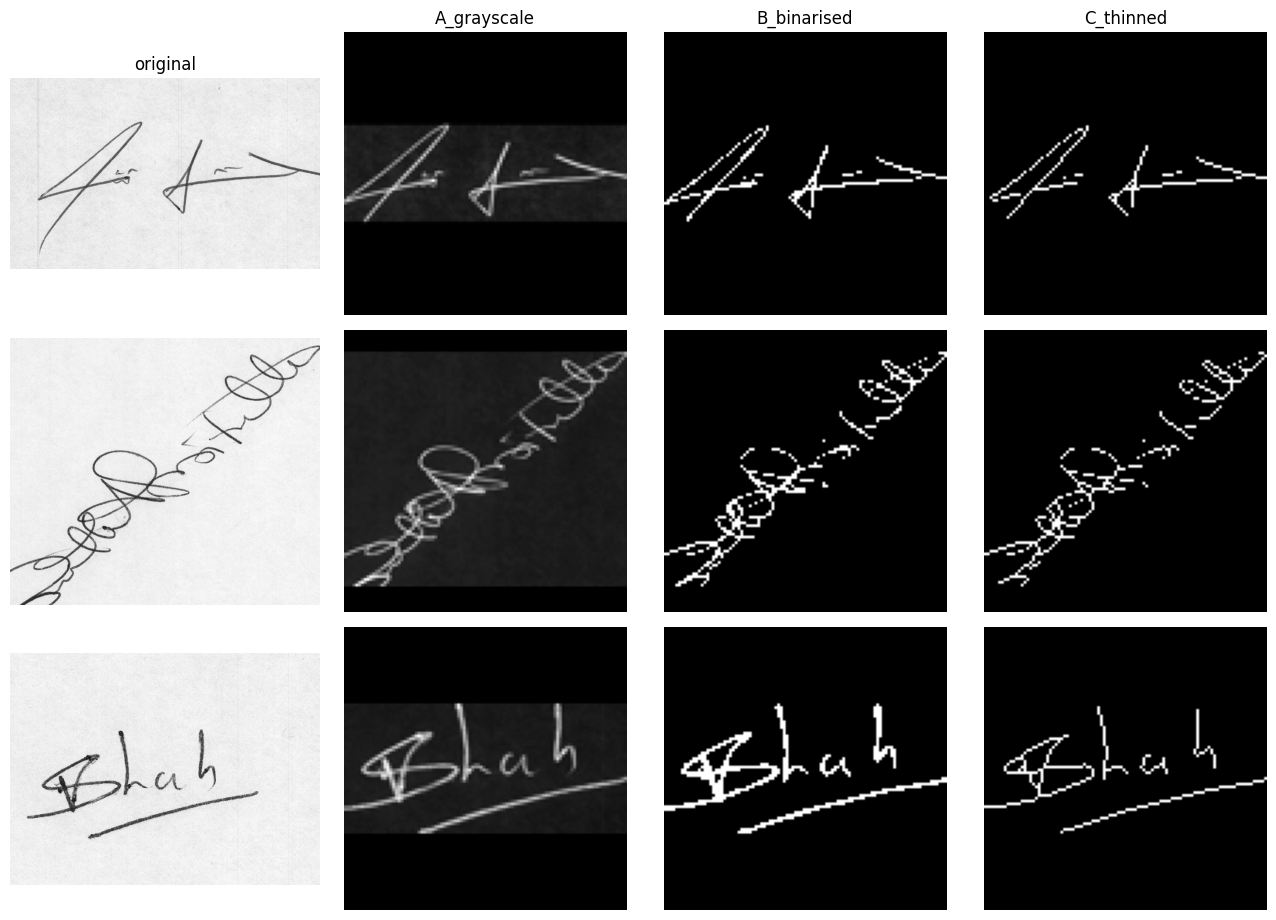

[timer] Part 3 preprocessing: 0.6s   (total 1.4s)


In [7]:
# visual check -- all three variants on the same three signatures
_demo_w = [w for w in (1, 7, 23) if w in writer_splits][:3] or list(writer_splits)[:3]
sample = [writer_splits[w]["train_genuine"][0] for w in _demo_w]
fig, ax = plt.subplots(len(sample), 4, figsize=(13, 3.1*len(sample)), squeeze=False)
for i, p in enumerate(sample):
    with Image.open(p) as im: orig = np.asarray(im.convert("L"))
    ax[i,0].imshow(orig, cmap="gray"); ax[i,0].set_title("original" if i==0 else "")
    for j, (name, fn) in enumerate(PREPROCESSORS.items(), start=1):
        ax[i,j].imshow(fn(p), cmap="gray"); ax[i,j].set_title(name if i==0 else "")
    for a in ax[i]: a.axis("off")
plt.tight_layout(); plt.show()
mark("Part 3 preprocessing")

---
## Part 4 — Feature extraction

In [8]:
HOG_PARAMS = dict(orientations=9, pixels_per_cell=(8,8),
                  cells_per_block=(2,2), block_norm="L2-Hys")

def raw_feature_fn(img01): return img01.flatten()
def hog_feature_fn(img01): return hog(img01, **HOG_PARAMS)

def build_features(paths, feature_fn, prep=None):
    prep = prep or preprocess_signature
    return np.array([feature_fn(prep(p).astype(np.float32)/255.0) for p in paths])

print("Extracting features (variant A)...")
X_train_raw    = build_features(train_files,        raw_feature_fn)
X_test_gen_raw = build_features(test_genuine_files, raw_feature_fn)
X_test_for_raw = build_features(test_forged_files,  raw_feature_fn)
X_train_hog    = build_features(train_files,        hog_feature_fn)
X_test_gen_hog = build_features(test_genuine_files, hog_feature_fn)
X_test_for_hog = build_features(test_forged_files,  hog_feature_fn)
print("RAW:", X_train_raw.shape, "| HOG:", X_train_hog.shape)
mark("Part 4 features")

Extracting features (variant A)...
RAW: (660, 10000) | HOG: (660, 4356)
[timer] Part 4 features: 36.5s   (total 37.8s)


---
## Part 5 — Standardisation

In [9]:
raw_scaler = StandardScaler().fit(X_train_raw)
hog_scaler = StandardScaler().fit(X_train_hog)
Xtr_raw, Xtg_raw, Xtf_raw = (raw_scaler.transform(x) for x in (X_train_raw, X_test_gen_raw, X_test_for_raw))
Xtr_hog, Xtg_hog, Xtf_hog = (hog_scaler.transform(x) for x in (X_train_hog, X_test_gen_hog, X_test_for_hog))
print("Scaled. RAW:", Xtr_raw.shape, "| HOG:", Xtr_hog.shape)
mark("Part 5 scaling")

Scaled. RAW: (660, 10000) | HOG: (660, 4356)
[timer] Part 5 scaling: 0.2s   (total 38.0s)


---
## Part 6 — Baseline (6buwan fixed global hyperparameters)

In [10]:
def _writer_idx(files, wid): return [i for i, p in enumerate(files) if get_writer_id(p) == wid]

def _metrics_from_preds(gp, fp, scores_g, scores_f):
    tp = int((gp == 1).sum()); fn = int((gp == -1).sum())
    fpos = int((fp == 1).sum()); tn = int((fp == -1).sum())
    frr = fn/(tp+fn); far = fpos/(fpos+tn)
    acc = (tp+tn)/(tp+tn+fpos+fn)
    prec = tp/(tp+fpos) if (tp+fpos) else 0.0
    rec  = tp/(tp+fn) if (tp+fn) else 0.0
    f1   = 2*prec*rec/(prec+rec) if (prec+rec) else 0.0
    auc  = roc_auc_score(np.r_[np.ones(len(scores_g)), np.zeros(len(scores_f))],
                         np.r_[scores_g, scores_f])
    return dict(FAR=far, FRR=frr, Accuracy=acc, Precision=prec, Recall=rec, F1=f1, AUC=auc)

def evaluate(X_train, X_tg, X_tf, params, label=""):
    """params: dict {nu,gamma} shared, OR dict wid -> {nu,gamma} per writer."""
    rows = []
    for wid in range(1, N_WRITERS+1):
        tr = _writer_idx(train_files, wid); tg = _writer_idx(test_genuine_files, wid)
        tf = _writer_idx(test_forged_files, wid)
        pr = params[wid] if wid in params else params
        m = OneClassSVM(kernel="rbf", nu=pr["nu"], gamma=pr["gamma"]).fit(X_train[tr])
        rows.append({"Writer": wid, "nu": pr["nu"], "gamma": pr["gamma"],
                     **_metrics_from_preds(m.predict(X_tg[tg]), m.predict(X_tf[tf]),
                                           m.decision_function(X_tg[tg]),
                                           m.decision_function(X_tf[tf]))})
    df = pd.DataFrame(rows)
    ov = {"Condition": label, **{k: df[k].mean() for k in
          ["FAR","FRR","Accuracy","Precision","Recall","F1","AUC"]}}
    ov["BalancedAccuracy"] = ((1-ov["FRR"]) + (1-ov["FAR"]))/2
    return df, ov

base_raw_df, base_raw = evaluate(Xtr_raw, Xtg_raw, Xtf_raw, V1_LOCKED["RAW"], "RAW fixed (6buwan)")
base_hog_df, base_hog = evaluate(Xtr_hog, Xtg_hog, Xtf_hog, V1_LOCKED["HOG"], "HOG fixed (6buwan)")
display(pd.DataFrame([base_raw, base_hog]))
mark("Part 6 baseline")

,Condition,FAR,FRR,Accuracy,Precision,Recall,F1,AUC,BalancedAccuracy
0,RAW fixed (6buwan),0.007576,0.795455,0.729798,0.876923,0.204545,0.315650,0.905240,0.598485
1,HOG fixed (6buwan),0.000000,0.813636,0.728788,0.909091,0.186364,0.292921,0.951199,0.593182


[timer] Part 6 baseline: 1.8s   (total 39.8s)


---
## Part 7 — Calibration (v2: with kernel non-degeneracy constraint)

### What changed from v1

v1 selected gamma values around 1e-11. Because `gamma_reference = 1/median_sq_dist`,
the **gamma multiplier is exactly the kernel-scale product** `gamma x median_sq_dist`
that 6buwan's `kernel_scale_check` tested. A multiplier of 1e-11 means the RBF kernel
evaluates to `exp(-1e-11) ~ 1.0` for every pair — a flat kernel, and a boundary that
no longer discriminates. The search was satisfying the acceptance target by destroying
the kernel rather than by placing a better boundary.

`KERNEL_SCALE_MIN` imposes a floor on that multiplier. One parameter fixes both the
degeneracy and the grid edge-binding, because they were the same failure.

### Why leave-one-out (retained from v1)

An earlier design set gamma from the within-writer median pairwise distance directly.
It failed — FRR stayed at 1.000 — because the median heuristic anchors the kernel to
the **train-to-train** distance scale while FRR is governed by the
**train-to-unseen-genuine** distance, which is systematically larger. Leave-one-out
inside enrollment is the only way to observe that larger scale without held-out or
forged data.

### Acceptance-target quantisation (explains the fallback count)

With 12 enrollment signatures, LOO acceptance can only take values k/12. A target of
0.70 therefore demands k >= 9, i.e. an effective target of **0.75**. This is a large
part of why ~40% of writers fell to the fallback tier in v1, and it is reported rather
than hidden.

In [11]:
EPS = 1e-12
NU_GRID           = (0.001, 0.002, 0.005, 0.01, 0.02, 0.05, 0.10, 0.20)
GAMMA_MULTIPLIERS = (0.01, 0.02, 0.05, 0.1, 0.2, 0.5, 1.0, 2.0, 5.0)
MAX_GRID_EXTENSIONS = 6


def _pairwise_sq_dists(X):
    n = X.shape[0]
    if n < 2: return np.array([])
    sq = np.sum(X**2, axis=1)
    d2 = sq[:,None] + sq[None,:] - 2.0*(X @ X.T)
    np.maximum(d2, 0.0, out=d2)
    return d2[np.triu_indices(n, k=1)]


def writer_gamma_reference(X):
    d2 = _pairwise_sq_dists(X)
    if d2.size == 0: return 1.0/max(X.shape[1], 1)
    return 1.0/max(float(np.median(d2)), EPS)


def _loo_acceptance(X, nu, gamma):
    """P(unseen genuine signature from this writer is accepted). Genuine-only."""
    n = X.shape[0]; acc = 0
    for i in range(n):
        m = OneClassSVM(kernel="rbf", nu=nu, gamma=gamma).fit(np.delete(X, i, axis=0))
        acc += int(m.predict(X[i:i+1])[0] == 1)
    return acc/n


def _self_exclusion(X, nu, gamma):
    m = OneClassSVM(kernel="rbf", nu=nu, gamma=gamma).fit(X)
    return float(np.mean(m.predict(X) == -1))


def _cohort_rejection(X, X_cohort, nu, gamma):
    """Rejection of OTHER writers' GENUINE signatures (surrogate impostors).
    Still genuine-only: an institution holds every customer's specimens."""
    if X_cohort is None or len(X_cohort) == 0: return float("nan")
    m = OneClassSVM(kernel="rbf", nu=nu, gamma=gamma).fit(X)
    return float(np.mean(m.predict(X_cohort) == -1))


def build_cohort(X_train, files, exclude_wid, per_writer=COHORT_PER_WRITER, rng=None):
    rng = rng or np.random.default_rng(RANDOM_SEED)
    by = {}
    for i, p in enumerate(files):
        w = get_writer_id(p)
        if w != exclude_wid: by.setdefault(w, []).append(i)
    picked = []
    for w, idxs in by.items():
        picked.extend(rng.choice(idxs, size=min(per_writer, len(idxs)), replace=False).tolist())
    return X_train[picked]


def _search(X, nus, mults, g_ref, target_accept, cache, X_cohort, kernel_scale_min):
    for m in mults:
        if kernel_scale_min is not None and m < kernel_scale_min:
            continue                      # degenerate kernel -- never a candidate
        gamma = g_ref*m
        for nu in nus:
            key = (round(float(nu),12), float(m))
            if key in cache: continue
            cache[key] = {"nu": nu, "gamma": gamma, "multiplier": m,
                          "loo_accept":     _loo_acceptance(X, nu, gamma),
                          "self_exclusion": _self_exclusion(X, nu, gamma),
                          "cohort_reject":  _cohort_rejection(X, X_cohort, nu, gamma)}
    allc = list(cache.values())
    return [r for r in allc if r["loo_accept"] >= target_accept], allc


def calibrate_writer(X_writer_train, X_cohort=None,
                     target_accept=TARGET_ACCEPT,
                     target_cohort_reject=TARGET_COHORT_REJECT,
                     nu_grid=NU_GRID, gamma_multipliers=GAMMA_MULTIPLIERS,
                     kernel_scale_min=KERNEL_SCALE_MIN,
                     auto_extend=True, max_extensions=MAX_GRID_EXTENSIONS):
    """Genuine-only calibration for ONE writer. No forged or labelled data is used."""
    g_ref = writer_gamma_reference(X_writer_train)
    nus, mults, cache, ext = list(nu_grid), list(gamma_multipliers), {}, 0
    passing, allc = _search(X_writer_train, nus, mults, g_ref, target_accept,
                            cache, X_cohort, kernel_scale_min)

    if auto_extend:
        while ext < max_extensions:
            if passing:
                bn = max(passing, key=lambda r: (0.0 if np.isnan(r["cohort_reject"]) else r["cohort_reject"],
                                                 r["self_exclusion"]))
            else:
                bn = max(allc, key=lambda r: (r["loo_accept"], r["self_exclusion"]))
            lo_m = min([m for m in mults if kernel_scale_min is None or m >= kernel_scale_min],
                       default=min(mults))
            at_min_g = np.isclose(bn["multiplier"], lo_m, rtol=1e-6)
            at_max_n = np.isclose(bn["nu"], max(nus))
            # with a kernel floor, extending gamma downward is pointless -- it is capped
            can_extend_g = at_min_g and (kernel_scale_min is None or lo_m > kernel_scale_min)
            if not (can_extend_g or at_max_n): break
            if can_extend_g:
                mults = sorted(set(mults + [max(lo_m/10, kernel_scale_min or 0),
                                            max(lo_m/30, kernel_scale_min or 0)]))
            if at_max_n:
                hi = max(nus); nus = sorted(set(nus + [min(hi*1.5, 0.5), min(hi*2.0, 0.5)]))
            ext += 1
            passing, allc = _search(X_writer_train, nus, mults, g_ref, target_accept,
                                    cache, X_cohort, kernel_scale_min)

    use_cohort = X_cohort is not None and len(X_cohort) > 0
    both = [r for r in passing if use_cohort and not np.isnan(r["cohort_reject"])
            and r["cohort_reject"] >= target_cohort_reject]

    if both:
        best, met, tier = max(both, key=lambda r: (r["cohort_reject"], r["self_exclusion"])), True, 1
    elif passing:
        key = ((lambda r: (r["cohort_reject"], r["self_exclusion"])) if use_cohort
               else (lambda r: (r["self_exclusion"], -r["gamma"])))
        best, met, tier = max(passing, key=key), True, 2
    else:
        best, met, tier = max(allc, key=lambda r: (r["loo_accept"],
                              0.0 if np.isnan(r["cohort_reject"]) else r["cohort_reject"])), False, 3

    return {"nu": best["nu"], "gamma": best["gamma"], "multiplier": best["multiplier"],
            "loo_accept": best["loo_accept"], "self_exclusion": best["self_exclusion"],
            "cohort_reject": best["cohort_reject"], "met_target": met,
            "selection_tier": tier, "gamma_reference": g_ref, "grid_extensions": ext}


def calibrate_corpus(X_train, files, target_accept=TARGET_ACCEPT,
                     kernel_scale_min=KERNEL_SCALE_MIN, seed=RANDOM_SEED, verbose=True):
    rng = np.random.default_rng(seed); calib = {}
    for wid in range(1, N_WRITERS+1):
        idx = _writer_idx(files, wid)
        assert len(idx) == N_TRAIN_GENUINE
        calib[wid] = calibrate_writer(X_train[idx],
                                      X_cohort=build_cohort(X_train, files, wid, rng=rng),
                                      target_accept=target_accept,
                                      kernel_scale_min=kernel_scale_min)
        if verbose and wid % 10 == 0: print(f"  ... writer {wid}/{N_WRITERS}", flush=True)
    return calib

print("Calibration defined. KERNEL_SCALE_MIN =", KERNEL_SCALE_MIN)

Calibration defined. KERNEL_SCALE_MIN = 0.01


---
## Part 8 — Run calibration, **both constrained and unconstrained**

Running both is the point. The unconstrained condition reproduces v1 (and its
degenerate kernels); the constrained one forbids them. Comparing the two shows whether
the v1 improvement survives a kernel that still discriminates — which is precisely the
question a panel will ask.

In [12]:
print("=== CONSTRAINED (v2: kernel floor active) ===")
print("RAW:");  calib_raw     = calibrate_corpus(Xtr_raw, train_files, kernel_scale_min=KERNEL_SCALE_MIN)
print("HOG:");  calib_hog     = calibrate_corpus(Xtr_hog, train_files, kernel_scale_min=KERNEL_SCALE_MIN)
mark("Part 8a constrained calibration")

print("\n=== UNCONSTRAINED (reproduces v1) ===")
print("RAW:");  calib_raw_unc = calibrate_corpus(Xtr_raw, train_files, kernel_scale_min=None)
print("HOG:");  calib_hog_unc = calibrate_corpus(Xtr_hog, train_files, kernel_scale_min=None)
mark("Part 8b unconstrained calibration")

calib_table = pd.DataFrame([
    {"Condition": cond, "Representation": rep, "Writer": wid,
     **{k: c[k] for k in ["nu","gamma","multiplier","loo_accept","cohort_reject",
                          "self_exclusion","selection_tier","grid_extensions"]}}
    for cond, reps in [("constrained", [("RAW", calib_raw), ("HOG", calib_hog)]),
                       ("unconstrained", [("RAW", calib_raw_unc), ("HOG", calib_hog_unc)])]
    for rep, calib in reps for wid, c in calib.items()])
display(calib_table.head(8))

=== CONSTRAINED (v2: kernel floor active) ===
RAW:
  ... writer 10/55
  ... writer 20/55
  ... writer 30/55
  ... writer 40/55
  ... writer 50/55
HOG:
  ... writer 10/55
  ... writer 20/55
  ... writer 30/55
  ... writer 40/55
  ... writer 50/55
[timer] Part 8a constrained calibration: 130.5s   (total 170.3s)

=== UNCONSTRAINED (reproduces v1) ===
RAW:
  ... writer 10/55
  ... writer 20/55
  ... writer 30/55
  ... writer 40/55
  ... writer 50/55
HOG:
  ... writer 10/55
  ... writer 20/55
  ... writer 30/55
  ... writer 40/55
  ... writer 50/55
[timer] Part 8b unconstrained calibration: 162.8s   (total 333.2s)


,Condition,Representation,Writer,nu,gamma,multiplier,loo_accept,cohort_reject,self_exclusion,selection_tier,grid_extensions
0,constrained,RAW,1,0.100,5.080992e-06,0.01,0.333333,1.000000,0.333333,3,0
1,constrained,RAW,2,0.100,4.264396e-06,0.01,0.083333,1.000000,0.666667,3,0
2,constrained,RAW,3,0.050,1.927933e-06,0.01,0.333333,1.000000,0.500000,3,0
3,constrained,RAW,4,0.020,4.707567e-06,0.02,0.166667,1.000000,0.666667,3,0
4,constrained,RAW,5,0.005,1.240620e-05,0.05,0.583333,0.972222,0.166667,3,0
5,constrained,RAW,6,0.005,3.775661e-05,0.20,0.416667,0.981481,0.333333,3,0
6,constrained,RAW,7,0.050,9.239834e-07,0.02,0.166667,0.981481,0.500000,3,0
7,constrained,RAW,8,0.010,2.826299e-06,0.05,0.416667,0.953704,0.333333,3,1


---
## Part 9 — Sanity checks (v2: adds kernel-degeneracy diagnosis)

In [13]:
def sanity_checks(calib, name):
    n = len(calib)
    nus   = np.array([c["nu"] for c in calib.values()])
    gams  = np.array([c["gamma"] for c in calib.values()])
    mults = np.array([c["multiplier"] for c in calib.values()])
    tiers = np.array([c["selection_tier"] for c in calib.values()])
    accs  = np.array([c["loo_accept"] for c in calib.values()])
    cohs  = np.array([c["cohort_reject"] for c in calib.values()])

    print(f"===== SANITY CHECKS: {name} =====")
    print(f"  [{'PASS' if gams.max()/max(gams.min(),EPS) > 2 else 'FAIL'}] gamma varies "
          f"({gams.max()/max(gams.min(),EPS):.1f}x spread)")
    print(f"  [{'PASS' if nus.std() > 1e-9 else 'FAIL'}] nu varies (sd={nus.std():.4f})")

    # kernel degeneracy -- the v1 failure
    degen = int((mults < 0.01).sum())
    print(f"  [{'PASS' if degen == 0 else 'FAIL'}] kernel non-degenerate "
          f"({degen}/{n} writers below multiplier 0.01)")
    print(f"        multiplier range: {mults.min():.3g} .. {mults.max():.3g}")

    # grid edges
    lo_g = int(np.isclose(mults, mults.min(), rtol=1e-3).sum())
    lo_n = int(np.isclose(nus, min(NU_GRID)).sum()); hi_n = int(np.isclose(nus, max(nus)).sum())
    edge = (lo_n + hi_n)/n > 0.20
    print(f"  [{'FAIL' if edge else 'PASS'}] nu not edge-binding (min {lo_n}, max {hi_n} of {n})")
    print(f"        writers at lowest available multiplier: {lo_g}/{n}")

    print(f"  tier 1 (both targets): {int((tiers==1).sum())}/{n}")
    print(f"  tier 2 (accept only) : {int((tiers==2).sum())}/{n}")
    print(f"  tier 3 (FALLBACK)    : {int((tiers==3).sum())}/{n}   <-- report this")
    print(f"  mean LOO acceptance  : {accs.mean():.3f}   "
          f"(effective target {ceil(TARGET_ACCEPT*N_TRAIN_GENUINE)/N_TRAIN_GENUINE:.3f} "
          f"after k/{N_TRAIN_GENUINE} quantisation)")
    print(f"  mean cohort rejection: {np.nanmean(cohs):.3f}\n")

for nm, cb in [("RAW constrained", calib_raw), ("HOG constrained", calib_hog),
               ("RAW unconstrained (v1)", calib_raw_unc), ("HOG unconstrained (v1)", calib_hog_unc)]:
    sanity_checks(cb, nm)
mark("Part 9 sanity")

===== SANITY CHECKS: RAW constrained =====
  [PASS] gamma varies (1141.7x spread)
  [PASS] nu varies (sd=0.0621)
  [PASS] kernel non-degenerate (0/55 writers below multiplier 0.01)
        multiplier range: 0.01 .. 1
  [PASS] nu not edge-binding (min 3, max 7 of 55)
        writers at lowest available multiplier: 31/55
  tier 1 (both targets): 0/55
  tier 2 (accept only) : 0/55
  tier 3 (FALLBACK)    : 55/55   <-- report this
  mean LOO acceptance  : 0.239   (effective target 0.750 after k/12 quantisation)
  mean cohort rejection: 0.935

===== SANITY CHECKS: HOG constrained =====
  [PASS] gamma varies (309.3x spread)
  [PASS] nu varies (sd=0.0671)
  [PASS] kernel non-degenerate (0/55 writers below multiplier 0.01)
        multiplier range: 0.01 .. 0.2
  [PASS] nu not edge-binding (min 2, max 1 of 55)
        writers at lowest available multiplier: 50/55
  tier 1 (both targets): 0/55
  tier 2 (accept only) : 0/55
  tier 3 (FALLBACK)    : 55/55   <-- report this
  mean LOO acceptance  : 

---
## Part 10 — Main comparison

In [14]:
cal_raw_df,     cal_raw     = evaluate(Xtr_raw, Xtg_raw, Xtf_raw, calib_raw,     "RAW calibrated (constrained)")
cal_hog_df,     cal_hog     = evaluate(Xtr_hog, Xtg_hog, Xtf_hog, calib_hog,     "HOG calibrated (constrained)")
cal_raw_unc_df, cal_raw_unc = evaluate(Xtr_raw, Xtg_raw, Xtf_raw, calib_raw_unc, "RAW calibrated (unconstrained=v1)")
cal_hog_unc_df, cal_hog_unc = evaluate(Xtr_hog, Xtg_hog, Xtf_hog, calib_hog_unc, "HOG calibrated (unconstrained=v1)")

n_g, n_f = len(test_genuine_files), len(test_forged_files)
trivial = [{"Condition":"Reject-all","FAR":0.0,"FRR":1.0,"Accuracy":n_f/(n_g+n_f),"BalancedAccuracy":0.5},
           {"Condition":"Accept-all","FAR":1.0,"FRR":0.0,"Accuracy":n_g/(n_g+n_f),"BalancedAccuracy":0.5}]

main_table = pd.DataFrame(trivial + [base_raw, cal_raw_unc, cal_raw,
                                     base_hog, cal_hog_unc, cal_hog])
cols = ["Condition","FAR","FRR","Accuracy","Precision","Recall","F1","AUC","BalancedAccuracy"]
print("MAIN COMPARISON (test: 12 genuine + 24 forged per writer)")
print("NOTE: compare AUC between constrained and unconstrained -- a drop in AUC means")
print("      the operating point improved while RANKING QUALITY got worse.\n")
display(main_table[cols])
mark("Part 10 main comparison")

MAIN COMPARISON (test: 12 genuine + 24 forged per writer)
NOTE: compare AUC between constrained and unconstrained -- a drop in AUC means
      the operating point improved while RANKING QUALITY got worse.



,Condition,FAR,FRR,Accuracy,Precision,Recall,F1,AUC,BalancedAccuracy
0,Reject-all,0.000000,1.000000,0.666667,NaN,NaN,NaN,NaN,0.500000
1,Accept-all,1.000000,0.000000,0.333333,NaN,NaN,NaN,NaN,0.500000
2,RAW fixed (6buwan),0.007576,0.795455,0.729798,0.876923,0.204545,0.315650,0.905240,0.598485
3,RAW calibrated (unconstrained=v1),0.051515,0.713636,0.727778,0.857181,0.286364,0.368499,0.879545,0.617424
4,RAW calibrated (constrained),0.007576,0.836364,0.716162,0.840559,0.163636,0.260079,0.901515,0.578030
5,HOG fixed (6buwan),0.000000,0.813636,0.728788,0.909091,0.186364,0.292921,0.951199,0.593182
6,HOG calibrated (unconstrained=v1),0.014394,0.669697,0.767172,0.888749,0.330303,0.418856,0.942929,0.657955
7,HOG calibrated (constrained),0.000000,0.840909,0.719697,0.872727,0.159091,0.256538,0.950442,0.579545


[timer] Part 10 main comparison: 3.8s   (total 337.0s)


---
## Part 11 — Operating-point sweep **(headline result)**

The acceptance target is not a hyperparameter to optimise away. It is the
institution's **risk dial**, and the contribution is that the dial operates *per
writer*, which one shared (nu, gamma) cannot do.

v2 tracks **AUC across the sweep**. If AUC falls as the target rises, the method is
buying its operating point by degrading the fit rather than by placing a better
boundary — which is exactly what the unconstrained v1 run was doing.

In [15]:
SWEEP_TARGETS = (0.50, 0.60, 0.70, 0.80, 0.90)

def sweep(X_train, X_tg, X_tf, label, kernel_scale_min):
    rows = []
    for t in SWEEP_TARGETS:
        cb = calibrate_corpus(X_train, train_files, target_accept=t,
                              kernel_scale_min=kernel_scale_min, verbose=False)
        _, ov = evaluate(X_train, X_tg, X_tf, cb, f"{label} t={t:.2f}")
        tiers = np.array([c["selection_tier"] for c in cb.values()])
        mults = np.array([c["multiplier"] for c in cb.values()])
        rows.append({**ov, "target_accept": t, "tier3": int((tiers==3).sum()),
                     "median_multiplier": float(np.median(mults))})
        print(f"  {label} t={t:.2f}  FRR={ov['FRR']:.4f}  FAR={ov['FAR']:.4f}  "
              f"BalAcc={ov['BalancedAccuracy']:.4f}  AUC={ov['AUC']:.4f}  "
              f"tier3={rows[-1]['tier3']}  med.mult={rows[-1]['median_multiplier']:.3g}", flush=True)
    return pd.DataFrame(rows)

print("RAW (constrained):"); sweep_raw = sweep(Xtr_raw, Xtg_raw, Xtf_raw, "RAW", KERNEL_SCALE_MIN)
print("\nHOG (constrained):"); sweep_hog = sweep(Xtr_hog, Xtg_hog, Xtf_hog, "HOG", KERNEL_SCALE_MIN)
mark("Part 11 sweep")

RAW (constrained):
  RAW t=0.50  FRR=0.8394  FAR=0.0076  BalAcc=0.5765  AUC=0.9022  tier3=53  med.mult=0.01
  RAW t=0.60  FRR=0.8364  FAR=0.0076  BalAcc=0.5780  AUC=0.9015  tier3=55  med.mult=0.01
  RAW t=0.70  FRR=0.8364  FAR=0.0076  BalAcc=0.5780  AUC=0.9015  tier3=55  med.mult=0.01
  RAW t=0.80  FRR=0.8364  FAR=0.0076  BalAcc=0.5780  AUC=0.9015  tier3=55  med.mult=0.01
  RAW t=0.90  FRR=0.8364  FAR=0.0076  BalAcc=0.5780  AUC=0.9015  tier3=55  med.mult=0.01

HOG (constrained):
  HOG t=0.50  FRR=0.8409  FAR=0.0000  BalAcc=0.5795  AUC=0.9504  tier3=55  med.mult=0.01
  HOG t=0.60  FRR=0.8409  FAR=0.0000  BalAcc=0.5795  AUC=0.9504  tier3=55  med.mult=0.01
  HOG t=0.70  FRR=0.8409  FAR=0.0000  BalAcc=0.5795  AUC=0.9504  tier3=55  med.mult=0.01
  HOG t=0.80  FRR=0.8409  FAR=0.0000  BalAcc=0.5795  AUC=0.9504  tier3=55  med.mult=0.01
  HOG t=0.90  FRR=0.8409  FAR=0.0000  BalAcc=0.5795  AUC=0.9504  tier3=55  med.mult=0.01
[timer] Part 11 sweep: 654.3s   (total 991.3s)


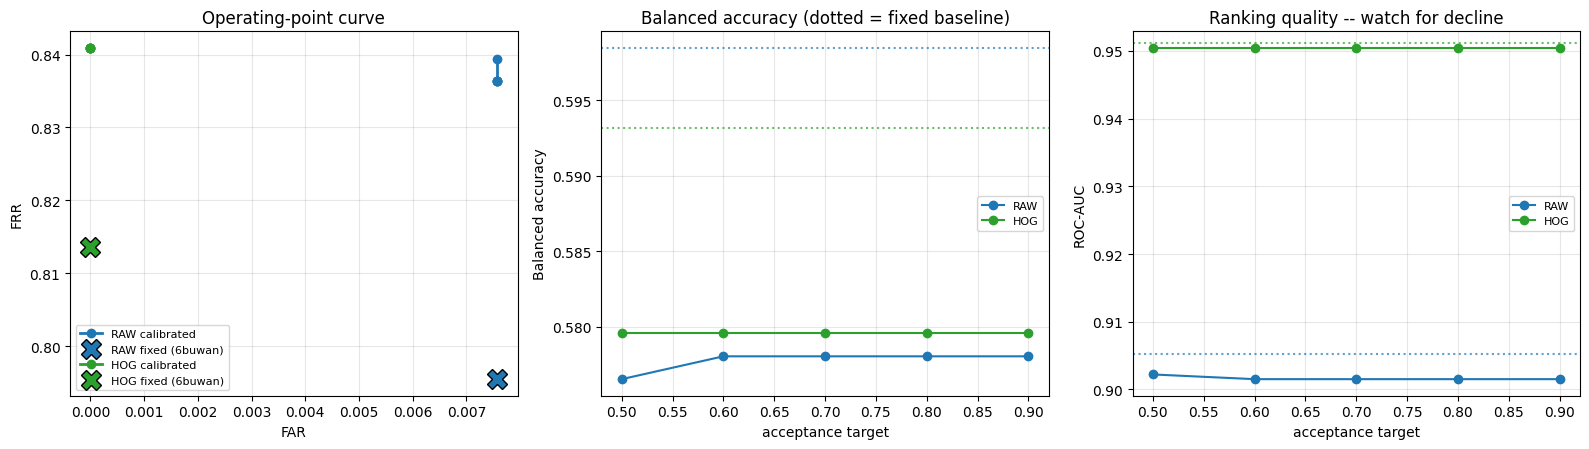

In [16]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))

for sw, base, nm, col in [(sweep_raw, base_raw, "RAW", "tab:blue"),
                          (sweep_hog, base_hog, "HOG", "tab:green")]:
    ax[0].plot(sw["FAR"], sw["FRR"], "o-", color=col, label=f"{nm} calibrated", linewidth=2)
    ax[0].plot(base["FAR"], base["FRR"], "X", color=col, markersize=14,
               markeredgecolor="k", label=f"{nm} fixed (6buwan)")
    ax[1].plot(sw["target_accept"], sw["BalancedAccuracy"], "o-", color=col, label=nm)
    ax[1].axhline(base["BalancedAccuracy"], color=col, linestyle=":", alpha=.7)
    ax[2].plot(sw["target_accept"], sw["AUC"], "o-", color=col, label=nm)
    ax[2].axhline(base["AUC"], color=col, linestyle=":", alpha=.7)

ax[0].set_xlabel("FAR"); ax[0].set_ylabel("FRR"); ax[0].set_title("Operating-point curve")
ax[1].set_xlabel("acceptance target"); ax[1].set_ylabel("Balanced accuracy")
ax[1].set_title("Balanced accuracy (dotted = fixed baseline)")
ax[2].set_xlabel("acceptance target"); ax[2].set_ylabel("ROC-AUC")
ax[2].set_title("Ranking quality -- watch for decline")
for a in ax: a.legend(fontsize=8); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

---
## Part 12 — Hypothesis testing and statistical power

In [17]:
def paired_test(cal_df, fix_df, metric, name, verbose=True):
    a, b = cal_df[metric].values, fix_df[metric].values
    d = a - b; informative = int((d != 0).sum())
    if informative == 0:
        if verbose: print(f"{name} {metric}: all pairs tied")
        return None
    W, p = stats.wilcoxon(a, b)
    better = int((d < 0).sum()) if metric in ("FAR","FRR") else int((d > 0).sum())
    if verbose:
        print(f"{name} {metric}:  {a.mean():.4f} vs {b.mean():.4f}  (delta {a.mean()-b.mean():+.4f})")
        print(f"   W={W:.1f}  p={p:.4g}  {'REJECT H0' if p<0.05 else 'fail to reject H0'}"
              f"   informative {informative}/{len(d)}   better on {better}, worse on {informative-better}")
    return {"name":name,"metric":metric,"p":p,"informative":informative,"better":better}

results = []
for nm, cdf, bdf in [("RAW constrained", cal_raw_df, base_raw_df),
                     ("HOG constrained", cal_hog_df, base_hog_df),
                     ("RAW unconstrained", cal_raw_unc_df, base_raw_df),
                     ("HOG unconstrained", cal_hog_unc_df, base_hog_df)]:
    for metric in ("FRR","FAR","F1","AUC"):
        r = paired_test(cdf, bdf, metric, nm)
        if r: results.append(r)
    print()
mark("Part 12 statistics")

RAW constrained FRR:  0.8364 vs 0.7955  (delta +0.0409)
   W=25.0  p=0.004636  REJECT H0   informative 19/55   better on 3, worse on 16
RAW constrained FAR: all pairs tied
RAW constrained F1:  0.2601 vs 0.3156  (delta -0.0556)
   W=24.0  p=0.00422  REJECT H0   informative 19/55   better on 3, worse on 16
RAW constrained AUC:  0.9015 vs 0.9052  (delta -0.0037)
   W=146.5  p=0.4598  fail to reject H0   informative 26/55   better on 18, worse on 8

HOG constrained FRR:  0.8409 vs 0.8136  (delta +0.0273)
   W=50.5  p=0.007103  REJECT H0   informative 23/55   better on 5, worse on 18
HOG constrained FAR: all pairs tied
HOG constrained F1:  0.2565 vs 0.2929  (delta -0.0364)
   W=51.5  p=0.008372  REJECT H0   informative 23/55   better on 5, worse on 18
HOG constrained AUC:  0.9504 vs 0.9512  (delta -0.0008)
   W=66.0  p=0.917  fail to reject H0   informative 16/55   better on 8, worse on 8

RAW unconstrained FRR:  0.7136 vs 0.7955  (delta -0.0818)
   W=59.0  p=0.01615  REJECT H0   informativ

In [18]:
def power_analysis(n_inf, observed_better, alpha=0.05, sims=200000, seed=RANDOM_SEED):
    if n_inf == 0: print("  no informative pairs"); return
    rng = np.random.default_rng(seed)
    crit = [k for k in range(n_inf+1)
            if stats.binomtest(k, n_inf, 0.5, alternative="two-sided").pvalue < alpha]
    print(f"  informative pairs {n_inf}   observed {observed_better}/{n_inf} "
          f"({observed_better/n_inf:.1%})")
    for k in range(n_inf//2, n_inf+1):
        if stats.binomtest(k, n_inf, 0.5, alternative="two-sided").pvalue < alpha:
            print(f"  smallest significant split: {k}/{n_inf} ({k/n_inf:.1%})"); break
    for p_true in (0.55,0.60,0.65,0.70,0.75,0.80):
        print(f"     P(better)={p_true:.2f} -> power "
              f"{np.isin(rng.binomial(n_inf, p_true, sims), crit).mean():.3f}")

for r in results:
    if r["metric"] == "FRR":
        print(f"POWER -- {r['name']} FRR"); power_analysis(r["informative"], r["better"]); print()

POWER -- RAW constrained FRR
  informative pairs 19   observed 3/19 (15.8%)
  smallest significant split: 15/19 (78.9%)
     P(better)=0.55 -> power 0.031
     P(better)=0.60 -> power 0.070
     P(better)=0.65 -> power 0.150
     P(better)=0.70 -> power 0.282
     P(better)=0.75 -> power 0.465
     P(better)=0.80 -> power 0.675

POWER -- HOG constrained FRR
  informative pairs 23   observed 5/23 (21.7%)
  smallest significant split: 17/23 (73.9%)
     P(better)=0.55 -> power 0.055
     P(better)=0.60 -> power 0.125
     P(better)=0.65 -> power 0.253
     P(better)=0.70 -> power 0.439
     P(better)=0.75 -> power 0.653
     P(better)=0.80 -> power 0.841

POWER -- RAW unconstrained FRR
  informative pairs 23   observed 14/23 (60.9%)
  smallest significant split: 17/23 (73.9%)
     P(better)=0.55 -> power 0.055
     P(better)=0.60 -> power 0.125
     P(better)=0.65 -> power 0.253
     P(better)=0.70 -> power 0.439
     P(better)=0.75 -> power 0.653
     P(better)=0.80 -> power 0.841

POWE

---
## Part 13 — Preprocessing experiment (A vs B vs C)

**Controlled:** identical split, identical calibration procedure, identical evaluation.
Only preprocessing varies. Features and scaler are rebuilt per variant — the scaler is
refit on that variant's **training data only**.

**Decision rule, fixed in advance:** judge on balanced accuracy and AUC, not on visual
sharpness. If a variant wins here it must then be re-run as the primary pipeline and
reported as such — selecting a variant on these test results and then presenting the
same numbers as an unbiased final evaluation would be selection bias. State in Ch. 3
that this comparison is exploratory.

**Runtime warning:** this runs calibration 2 representations x 3 variants = 6 times.
Expect roughly 6x the Part 8 runtime. Set `RUN_PREPROCESSING_EXPERIMENT = False` to skip.

In [19]:
RUN_PREPROCESSING_EXPERIMENT = True

def run_variant(prep_name, prep_fn):
    out = []
    Xtr_r = build_features(train_files,        raw_feature_fn, prep_fn)
    Xtg_r = build_features(test_genuine_files, raw_feature_fn, prep_fn)
    Xtf_r = build_features(test_forged_files,  raw_feature_fn, prep_fn)
    Xtr_h = build_features(train_files,        hog_feature_fn, prep_fn)
    Xtg_h = build_features(test_genuine_files, hog_feature_fn, prep_fn)
    Xtf_h = build_features(test_forged_files,  hog_feature_fn, prep_fn)

    for rep, (Xa, Xb, Xc) in [("RAW", (Xtr_r, Xtg_r, Xtf_r)), ("HOG", (Xtr_h, Xtg_h, Xtf_h))]:
        sc = StandardScaler().fit(Xa)                     # training data only
        A, B, Cc = sc.transform(Xa), sc.transform(Xb), sc.transform(Xc)
        _, fixed = evaluate(A, B, Cc, V1_LOCKED[rep], f"{prep_name}/{rep} fixed")
        cb = calibrate_corpus(A, train_files, kernel_scale_min=KERNEL_SCALE_MIN, verbose=False)
        _, cal = evaluate(A, B, Cc, cb, f"{prep_name}/{rep} calibrated")
        t3 = int(sum(c["selection_tier"] == 3 for c in cb.values()))
        out += [{**fixed, "Variant": prep_name, "Representation": rep, "Mode": "fixed", "tier3": None},
                {**cal,   "Variant": prep_name, "Representation": rep, "Mode": "calibrated", "tier3": t3}]
        print(f"  {prep_name:12s} {rep}  fixed BalAcc={fixed['BalancedAccuracy']:.4f} AUC={fixed['AUC']:.4f}"
              f"   calibrated BalAcc={cal['BalancedAccuracy']:.4f} AUC={cal['AUC']:.4f} tier3={t3}", flush=True)
    return out

if RUN_PREPROCESSING_EXPERIMENT:
    rows = []
    for nm, fn in PREPROCESSORS.items():
        print(f"\n--- variant {nm} ---")
        rows += run_variant(nm, fn)
    prep_table = pd.DataFrame(rows)[
        ["Variant","Representation","Mode","FAR","FRR","Accuracy","F1","AUC","BalancedAccuracy","tier3"]]
    display(prep_table)
    mark("Part 13 preprocessing experiment")
else:
    prep_table = None
    print("Skipped.")


--- variant A_grayscale ---
  A_grayscale  RAW  fixed BalAcc=0.5985 AUC=0.9052   calibrated BalAcc=0.5780 AUC=0.9015 tier3=55
  A_grayscale  HOG  fixed BalAcc=0.5932 AUC=0.9512   calibrated BalAcc=0.5795 AUC=0.9504 tier3=55

--- variant B_binarised ---
  B_binarised  RAW  fixed BalAcc=0.5212 AUC=0.6888   calibrated BalAcc=0.5102 AUC=0.6863 tier3=55
  B_binarised  HOG  fixed BalAcc=0.6034 AUC=0.8489   calibrated BalAcc=0.6129 AUC=0.8514 tier3=55

--- variant C_thinned ---
  C_thinned    RAW  fixed BalAcc=0.5023 AUC=0.6904   calibrated BalAcc=0.4947 AUC=0.6818 tier3=55
  C_thinned    HOG  fixed BalAcc=0.6167 AUC=0.8485   calibrated BalAcc=0.6212 AUC=0.8510 tier3=55


,Variant,Representation,Mode,FAR,FRR,Accuracy,F1,AUC,BalancedAccuracy,tier3
0,A_grayscale,RAW,fixed,0.007576,0.795455,0.729798,0.315650,0.905240,0.598485,NaN
1,A_grayscale,RAW,calibrated,0.007576,0.836364,0.716162,0.260079,0.901515,0.578030,55.0
2,A_grayscale,HOG,fixed,0.000000,0.813636,0.728788,0.292921,0.951199,0.593182,NaN
3,A_grayscale,HOG,calibrated,0.000000,0.840909,0.719697,0.256538,0.950442,0.579545,55.0
4,B_binarised,RAW,fixed,0.183333,0.774242,0.619697,0.254232,0.688763,0.521212,NaN
5,B_binarised,RAW,calibrated,0.171970,0.807576,0.616162,0.213213,0.686301,0.510227,55.0
6,B_binarised,HOG,fixed,0.070455,0.722727,0.712121,0.372684,0.848927,0.603409,NaN
7,B_binarised,HOG,calibrated,0.059091,0.715152,0.722222,0.393498,0.851389,0.612879,55.0
8,C_thinned,RAW,fixed,0.180303,0.815152,0.608081,0.210463,0.690404,0.502273,NaN
9,C_thinned,RAW,calibrated,0.160606,0.850000,0.609596,0.160451,0.681755,0.494697,55.0


[timer] Part 13 preprocessing experiment: 519.5s   (total 1511.2s)


CALIBRATED results by preprocessing variant:


BalancedAccuracy                 AUC          
Representation              HOG       RAW       HOG       RAW
Variant                                                      
A_grayscale            0.579545  0.578030  0.950442  0.901515
B_binarised            0.612879  0.510227  0.851389  0.686301
C_thinned              0.621212  0.494697  0.851010  0.681755

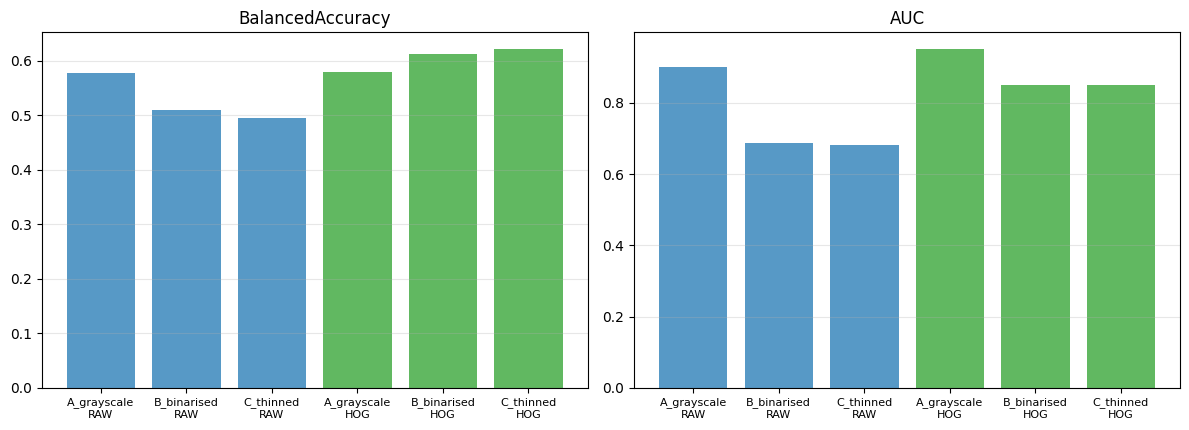

In [20]:
if prep_table is not None:
    piv = prep_table[prep_table.Mode == "calibrated"].pivot(
        index="Variant", columns="Representation", values=["BalancedAccuracy","AUC"])
    print("CALIBRATED results by preprocessing variant:")
    display(piv)

    fig, ax = plt.subplots(1, 2, figsize=(12, 4.4))
    for j, metric in enumerate(["BalancedAccuracy", "AUC"]):
        for rep, col in [("RAW","tab:blue"), ("HOG","tab:green")]:
            sub = prep_table[(prep_table.Representation==rep) & (prep_table.Mode=="calibrated")]
            ax[j].bar([f"{v}\n{rep}" for v in sub.Variant], sub[metric], color=col, alpha=.75)
        ax[j].set_title(metric); ax[j].tick_params(axis="x", labelsize=8); ax[j].grid(alpha=.3, axis="y")
    plt.tight_layout(); plt.show()

---
## Part 14 — Occlusion-based decision attribution

Grad-CAM, Integrated Gradients and DeepLIFT all require gradients of the output with
respect to the input. An RBF One-Class SVM exposes no such path, so **none of them can
be applied here at all.** Occlusion attribution is model-agnostic — it needs only the
ability to score an input.

The occluded image is passed through the **same feature extractor and the same
preprocessing variant** as the model being explained. For HOG this matters: masking
pixels changes the gradient structure of surrounding cells, which recomputing captures
and which zeroing entries of a precomputed HOG vector would not.

In [21]:
def occlusion_attribution(img01, feature_fn, scaler, model, patch_size=12, stride=6,
                          occlusion_value=0.0):
    """Returns (heatmap, base_score). Positive = region supported the 'genuine' decision."""
    H, W = img01.shape
    base_feat  = scaler.transform(feature_fn(img01).reshape(1,-1))
    base_score = float(model.decision_function(base_feat)[0])

    pos = [(t,l) for t in range(0, max(H-patch_size,0)+1, stride)
                 for l in range(0, max(W-patch_size,0)+1, stride)]
    feats = np.empty((len(pos), base_feat.shape[1]))
    for k,(t,l) in enumerate(pos):
        q = img01.copy(); q[t:t+patch_size, l:l+patch_size] = occlusion_value
        feats[k] = scaler.transform(feature_fn(q).reshape(1,-1))[0]
    scores = model.decision_function(feats)

    acc = np.zeros((H,W)); cnt = np.zeros((H,W))
    for k,(t,l) in enumerate(pos):
        acc[t:t+patch_size, l:l+patch_size] += base_score - float(scores[k])
        cnt[t:t+patch_size, l:l+patch_size] += 1
    cnt[cnt==0] = 1
    return acc/cnt, base_score


def overlay_heatmap(img01, hm, alpha=0.5):
    import matplotlib.cm as cm
    m = np.max(np.abs(hm)); norm = hm/m if m>0 else np.zeros_like(hm)
    col = cm.get_cmap("bwr")((norm+1)/2)[...,:3]
    g = np.clip(img01,0,1); base = np.dstack([g,g,g])
    return np.clip((1-alpha)*base + alpha*col, 0, 1)


def attribution_on_ink(hm, img01, ink_threshold=0.2):
    tot = np.abs(hm).sum()
    return 0.0 if tot<=0 else float(np.abs(hm)[img01>ink_threshold].sum()/tot)


def fit_writer_model(wid, representation="HOG", calibrated=True):
    if representation == "HOG":
        Xt, sc, cb, fn, fx = Xtr_hog, hog_scaler, calib_hog, hog_feature_fn, V1_LOCKED["HOG"]
    else:
        Xt, sc, cb, fn, fx = Xtr_raw, raw_scaler, calib_raw, raw_feature_fn, V1_LOCKED["RAW"]
    tr = _writer_idx(train_files, wid)
    pr = cb[wid] if calibrated else fx
    return OneClassSVM(kernel="rbf", nu=pr["nu"], gamma=pr["gamma"]).fit(Xt[tr]), sc, fn

print("Attribution defined.")

Attribution defined.


In [22]:
# demo cases: GENUINE signatures the fixed model rejects and the calibrated model accepts
def find_demo_cases(representation="HOG", limit=5):
    cases = []
    X_tg = Xtg_hog if representation=="HOG" else Xtg_raw
    for wid in range(1, N_WRITERS+1):
        tg = _writer_idx(test_genuine_files, wid)
        mf,_,_ = fit_writer_model(wid, representation, calibrated=False)
        mc,_,_ = fit_writer_model(wid, representation, calibrated=True)
        pf, pc = mf.predict(X_tg[tg]), mc.predict(X_tg[tg])
        for j,i in enumerate(tg):
            if pf[j]==-1 and pc[j]==1:
                cases.append({"writer":wid, "path":test_genuine_files[i]})
                if len(cases)>=limit: return cases
    return cases

demo_cases = find_demo_cases("HOG", 5)
print(f"{len(demo_cases)} demo cases (genuine; fixed REJECTS, calibrated ACCEPTS)")
for c in demo_cases: print(f"   writer {c['writer']}: {Path(c['path']).name}")

5 demo cases (genuine; fixed REJECTS, calibrated ACCEPTS)
   writer 17: original_17_5.png
   writer 29: original_29_5.png
   writer 30: original_30_1.png
   writer 52: original_52_4.png
   writer 52: original_52_11.png


Writer 17 | GENUINE signature
  6buwan fixed : -0.00003 -> REJECT
  calibrated   : +0.00003 -> ACCEPT
  nu 0.1000  gamma 5.276e-06  multiplier 0.01
  attribution on ink: 18.7% (ink = 5.6% of pixels)


/tmp/ipykernel_18997/1855463951.py:27: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  col = cm.get_cmap("bwr")((norm+1)/2)[...,:3]


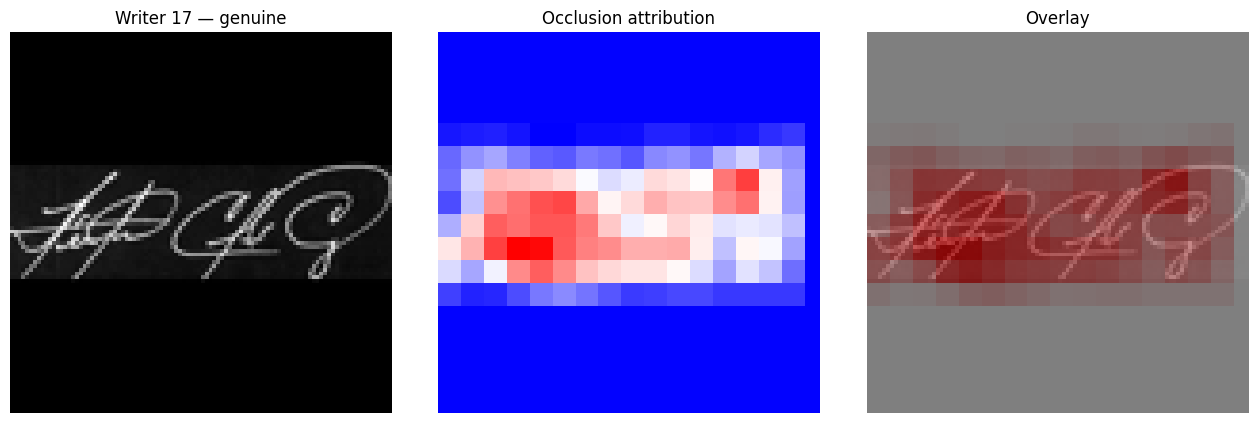

[timer] Part 14 attribution: 1.5s   (total 1512.7s)


In [23]:
if demo_cases:
    case = demo_cases[0]; wid, path = case["writer"], case["path"]
    img01 = preprocess_signature(path).astype(np.float32)/255.0
    mc, sc, fn = fit_writer_model(wid, "HOG", True)
    mf, _, _   = fit_writer_model(wid, "HOG", False)
    hm, s_cal = occlusion_attribution(img01, fn, sc, mc)
    s_fix = float(mf.decision_function(sc.transform(fn(img01).reshape(1,-1)))[0])

    print(f"Writer {wid} | GENUINE signature")
    print(f"  6buwan fixed : {s_fix:+.5f} -> {'ACCEPT' if s_fix>0 else 'REJECT'}")
    print(f"  calibrated   : {s_cal:+.5f} -> {'ACCEPT' if s_cal>0 else 'REJECT'}")
    print(f"  nu {calib_hog[wid]['nu']:.4f}  gamma {calib_hog[wid]['gamma']:.3e}  "
          f"multiplier {calib_hog[wid]['multiplier']:.3g}")
    print(f"  attribution on ink: {attribution_on_ink(hm, img01):.1%} "
          f"(ink = {(img01>0.2).mean():.1%} of pixels)")

    fig, ax = plt.subplots(1,3, figsize=(13,4.2))
    ax[0].imshow(img01, cmap="gray");         ax[0].set_title(f"Writer {wid} — genuine")
    ax[1].imshow(hm, cmap="bwr");             ax[1].set_title("Occlusion attribution")
    ax[2].imshow(overlay_heatmap(img01, hm)); ax[2].set_title("Overlay")
    for a in ax: a.axis("off")
    plt.tight_layout(); plt.show()
else:
    print("No demo cases found.")
mark("Part 14 attribution")

---
## Part 15 — Export and runtime report

In [24]:
OUT = Path("/content/drive/MyDrive/4buwan_results_v2"); OUT.mkdir(parents=True, exist_ok=True)
main_table.to_csv(OUT/"table_main_comparison.csv", index=False)
calib_table.to_csv(OUT/"table_per_writer_calibration.csv", index=False)
sweep_raw.to_csv(OUT/"table_sweep_raw.csv", index=False)
sweep_hog.to_csv(OUT/"table_sweep_hog.csv", index=False)
for nm, df in [("raw_calibrated",cal_raw_df), ("hog_calibrated",cal_hog_df),
               ("raw_fixed",base_raw_df),     ("hog_fixed",base_hog_df),
               ("raw_calibrated_unconstrained",cal_raw_unc_df),
               ("hog_calibrated_unconstrained",cal_hog_unc_df)]:
    df.to_csv(OUT/f"per_writer_{nm}.csv", index=False)
if prep_table is not None:
    prep_table.to_csv(OUT/"table_preprocessing_experiment.csv", index=False)
print("Saved to", OUT)
for f in sorted(OUT.glob("*.csv")): print("  ", f.name)

Saved to /content/drive/MyDrive/4buwan_results_v2
   per_writer_hog_calibrated.csv
   per_writer_hog_calibrated_unconstrained.csv
   per_writer_hog_fixed.csv
   per_writer_raw_calibrated.csv
   per_writer_raw_calibrated_unconstrained.csv
   per_writer_raw_fixed.csv
   table_main_comparison.csv
   table_per_writer_calibration.csv
   table_preprocessing_experiment.csv
   table_sweep_hog.csv
   table_sweep_raw.csv


In [25]:
# ================= RUNTIME REPORT =================
total = time.time() - NB_T0
h, rem = divmod(total, 3600); m, s = divmod(rem, 60)

print("="*58)
print("RUNTIME REPORT")
print("="*58)
for k, v in SECTION_TIMES.items():
    if k == "_last": continue
    print(f"  {k:<42s} {v:8.1f}s  ({v/60:5.1f} min)")
print("-"*58)
print(f"  {'TOTAL':<42s} {total:8.1f}s")
print(f"  {'':<42s} {int(h)}h {int(m)}m {int(s)}s")
print("="*58)

RUNTIME REPORT
  Part 1 dataset                                  0.1s  (  0.0 min)
  Part 2 split                                    0.7s  (  0.0 min)
  Part 3 preprocessing                            0.6s  (  0.0 min)
  Part 4 features                                36.5s  (  0.6 min)
  Part 5 scaling                                  0.2s  (  0.0 min)
  Part 6 baseline                                 1.8s  (  0.0 min)
  Part 8a constrained calibration               130.5s  (  2.2 min)
  Part 8b unconstrained calibration             162.8s  (  2.7 min)
  Part 9 sanity                                   0.0s  (  0.0 min)
  Part 10 main comparison                         3.8s  (  0.1 min)
  Part 11 sweep                                 654.3s  ( 10.9 min)
  Part 12 statistics                              0.4s  (  0.0 min)
  Part 13 preprocessing experiment              519.5s  (  8.7 min)
  Part 14 attribution                             1.5s  (  0.0 min)
---------------------------------

---
## What to report back

1. **Part 9** — does the constrained run still show degenerate kernels, and what is the tier-3 count under each condition?
2. **Part 10** — constrained vs unconstrained vs fixed. **Watch AUC:** if constrained AUC holds near the fixed baseline while FRR still drops, the improvement is real rather than bought by flattening the kernel.
3. **Part 11** — does AUC decline as the acceptance target rises?
4. **Part 12** — p-values and informative-pair counts for the constrained condition.
5. **Part 13** — which preprocessing variant wins on balanced accuracy and AUC.
6. **Part 15** — total runtime.

### The question this version answers

v1 showed FRR falling 81% -> 43% with AUC falling 0.951 -> 0.920. The open question
was whether the gain was a genuinely better per-writer boundary or an artifact of a
collapsing kernel. **If the constrained run keeps most of the FRR gain while holding
AUC, the contribution stands.** If the gain disappears once the kernel must remain
non-degenerate, that is a real finding too — and far better to learn now than at the
defence.

### Naming

- `6buwan` — prior comparative study (RAW vs HOG)
- `4buwan_calibration_v1` — first calibration run; degenerate kernels
- `4buwan_calibration_v2` — this notebook